# CardioSense — Model Explainability (SHAP & LIME)

**Project:** CardioSense (Explainable ML System for 10-Year Coronary Heart Disease Risk Prediction)  
**Model Artifact:** `models/best_model.pkl` (`imblearn.pipeline.Pipeline` with `ColumnTransformer` + `SMOTE` + `LogisticRegression`)  
**Reusable Explainability Module:** `src/explain.py`

### Objectives
1. Load the saved pipeline from `models/best_model.pkl` and reconstruct the exact held-out test set (`848` patients).
2. Generate **Global SHAP Explanations** (beeswarm summary plot + mean `|SHAP|` bar plot) on preprocessed features using `shap.LinearExplainer` with readable feature names.
3. Generate **Local SHAP Waterfall Plots** for one high-risk patient and one low-risk patient from the held-out test set.
4. Generate **LIME Explanations** (`LimeTabularExplainer`) for the exact same two patients.
5. Implement and test `explain_patient(patient_df)` returning predicted probability and top 5 contributing features with risk direction.
6. Compare **SHAP vs. LIME** conceptually and empirically on our patients, saving all figures to `reports/`.


In [6]:
import json
import sys
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

# Resolve project root whether run from project root or notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data" / "framingham.csv").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.train import load_and_split_data
from src.explain import (
    FEATURE_ORDER,
    READABLE_FEATURE_NAMES,
    build_lime_explainer,
    build_shap_explainer,
    compute_shap_values,
    explain_patient,
    load_model_and_metadata,
    plot_lime_comparison,
    plot_shap_bar,
    plot_shap_beeswarm,
    plot_shap_waterfall,
    preprocess_features,
    select_representative_patients,
)

DATA_PATH = PROJECT_ROOT / "data" / "framingham.csv"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

pipeline, metadata = load_model_and_metadata(MODELS_DIR)
tuned_threshold = float(metadata.get("tuned_threshold", 0.41))
X_train, X_test, y_train, y_test = load_and_split_data(DATA_PATH)

print(f"Loaded model:      {metadata.get('best_model')} (tuned threshold = {tuned_threshold:.2f})")
print(f"Pipeline steps:    {[name for name, _ in pipeline.steps]}")
print(f"Train / Test size: {len(X_train):,} / {len(X_test):,} rows")


Loaded model:      Logistic Regression (tuned threshold = 0.41)
Pipeline steps:    ['preprocessor', 'smote', 'classifier']
Train / Test size: 3,390 / 848 rows


### Interpretation — Loaded Model & Evaluation Split

- We load the serialized `imblearn` pipeline (`preprocessor` -> `smote` -> `LogisticRegression`) from `models/best_model.pkl` along with `tuned_threshold = 0.41`.
- Reusing `load_and_split_data()` with `RANDOM_STATE = 42` reproduces the exact `3,390`-row training split (used as the background distribution for SHAP/LIME) and `848`-row held-out test set.


## 1. Global SHAP Explanations (Beeswarm & Mean `|SHAP|` Bar Plot)

Because the winning classifier is `LogisticRegression`, we use **`shap.LinearExplainer`** with an independent masker spanning all `3,390` preprocessed training rows (zero subsampling approximation). Explanations are computed on the preprocessed test matrix (`848 x 15`) with readable clinical feature labels.


,Feature,Mean |SHAP|
0,Age (years),0.4830
1,Cigarettes / Day,0.2263
2,Systolic BP (mmHg),0.1868
3,Sex (Male = 1),0.1311
4,Total Cholesterol (mg/dL),0.0815
5,Prevalent Hypertension (1 = Yes),0.0711
6,Glucose (mg/dL),0.0625
7,Diastolic BP (mmHg),0.0478
8,Education Level (1–4),0.0324
9,Heart Rate (bpm),0.0134


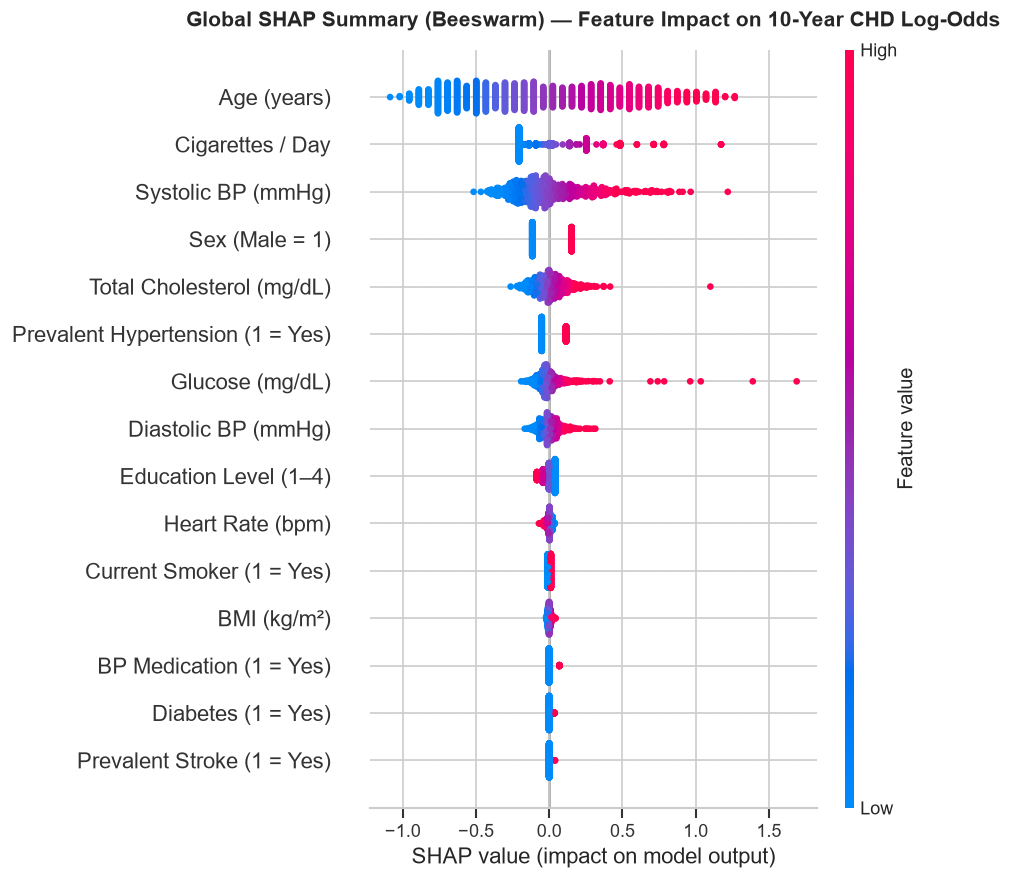

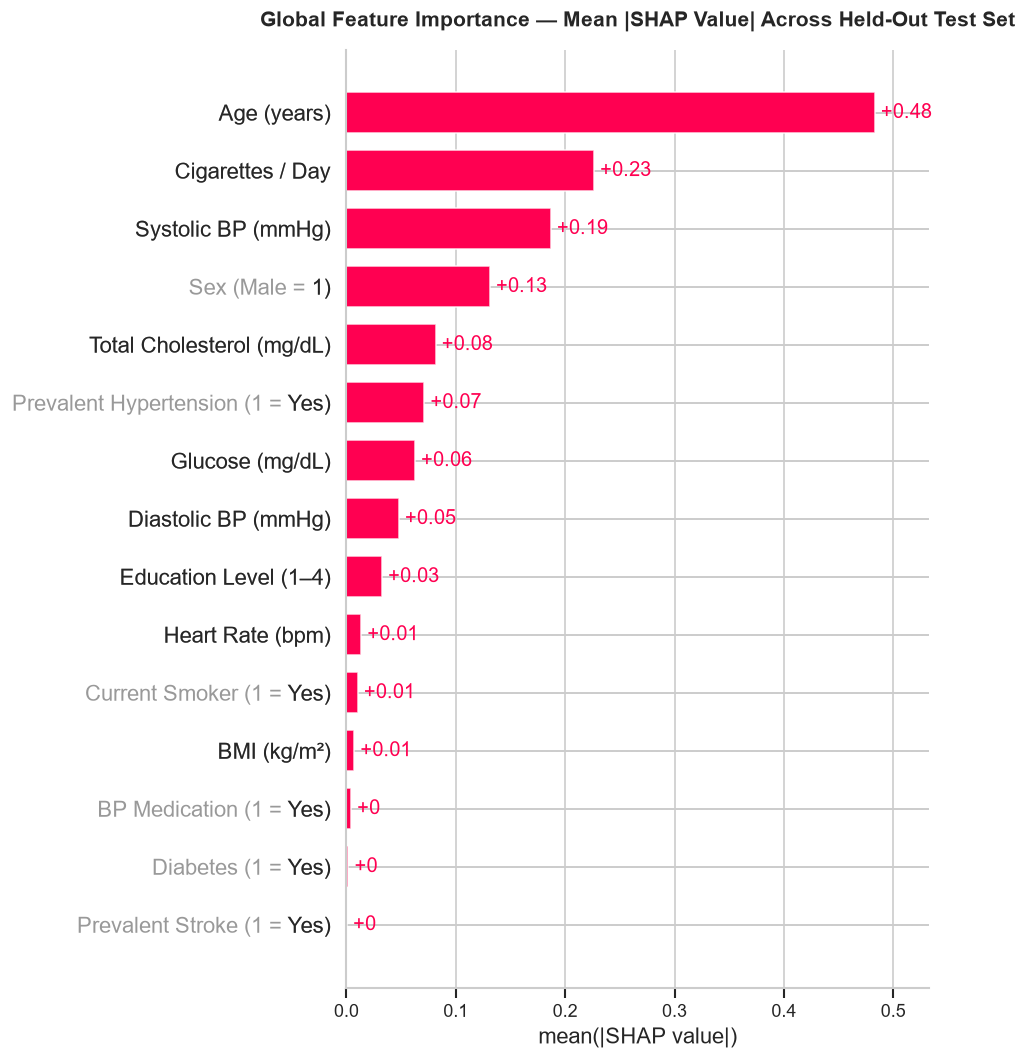

In [7]:
shap_explainer, X_train_proc = build_shap_explainer(pipeline, X_train)
X_test_proc = preprocess_features(pipeline, X_test, readable_names=True)
shap_values = compute_shap_values(shap_explainer, X_test_proc)

mean_abs_shap = (
    pd.DataFrame({
        "Feature": shap_values.feature_names,
        "Mean |SHAP|": abs(shap_values.values).mean(axis=0),
    })
    .sort_values("Mean |SHAP|", ascending=False)
    .reset_index(drop=True)
)
display(mean_abs_shap.round(4))

fig_bee = plot_shap_beeswarm(shap_values, save_path=REPORTS_DIR / "shap_summary_beeswarm.png")
plt.show()

fig_bar = plot_shap_bar(shap_values, save_path=REPORTS_DIR / "shap_feature_importance_bar.png")
plt.show()


### Interpretation — Global SHAP Findings

- **Top global risk drivers:** **`Age (years)`** (`mean |SHAP| = 0.48`), **`Cigarettes / Day`** (`0.23`), **`Systolic BP (mmHg)`** (`0.19`), **`Sex (Male = 1)`** (`0.13`), and **`Total Cholesterol (mg/dL)`** (`0.08`), followed by `Prevalent Hypertension` (`0.07`), `Glucose` (`0.06`), and `Diastolic BP` (`0.05`).
- **Directionality in the beeswarm plot:** High feature values (pink/red dots) for **Age**, **Systolic BP**, **Cigarettes / Day**, **Male Sex**, **Total Cholesterol**, and **Glucose** push SHAP values positively (increasing predicted 10-year CHD log-odds), whereas **Education Level** shows a mild protective negative tilt (higher education slightly reduces predicted log-odds).
- **Collinearity behavior:** Notice that `Current Smoker (1 = Yes)` (`0.01`) and `Diabetes (1 = Yes)` (`~0.00`) carry small weights because `Cigarettes / Day` and `Glucose (mg/dL)` already capture the continuous dose-response signal and L1/L2 regularization concentrated weight onto the continuous predictors.


## 2. Local SHAP Waterfall Explanations (High-Risk vs. Low-Risk Test Patients)

We select one true high-risk patient (`TenYearCHD = 1`) and one true low-risk patient (`TenYearCHD = 0`) from the held-out test set, inspect their raw clinical measurements, and plot their local SHAP waterfall explanations.


,High-Risk Patient,Low-Risk Patient
Sex (Male = 1),1.00,0.00
Age (years),61.00,35.00
Education Level (1–4),1.00,2.00
Current Smoker (1 = Yes),1.00,0.00
Cigarettes / Day,20.00,0.00
BP Medication (1 = Yes),0.00,0.00
Prevalent Stroke (1 = Yes),0.00,0.00
Prevalent Hypertension (1 = Yes),1.00,0.00
Diabetes (1 = Yes),0.00,0.00
Total Cholesterol (mg/dL),220.00,170.00


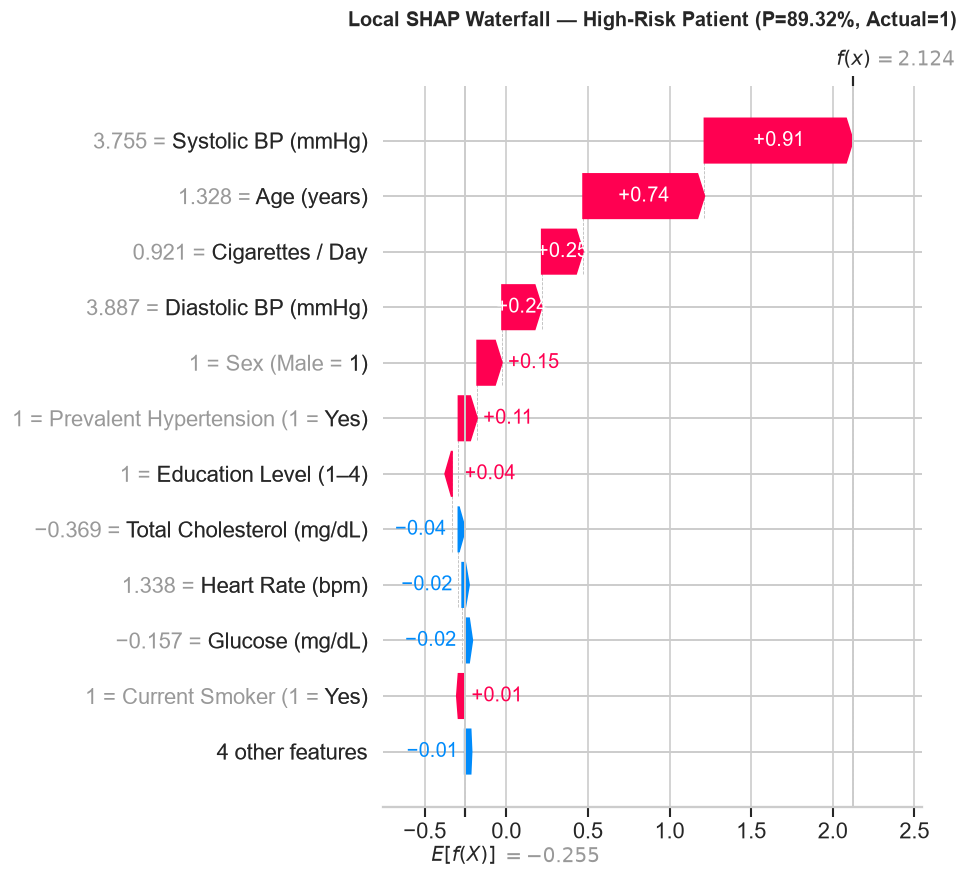

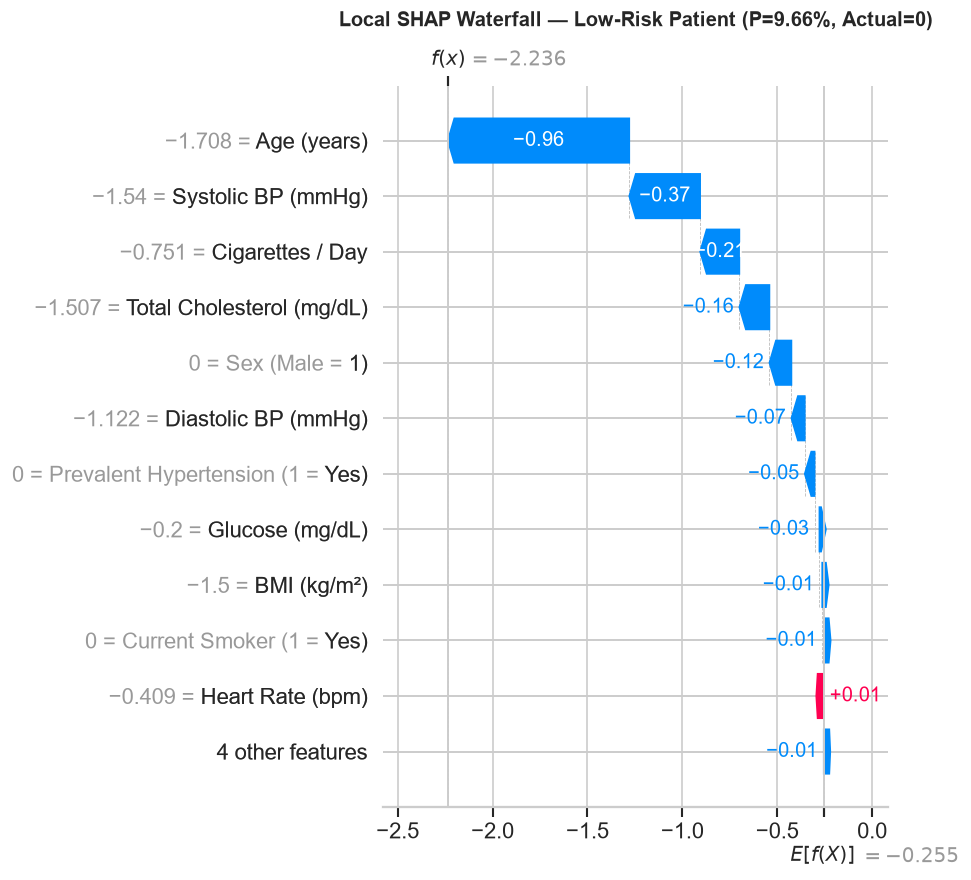

In [8]:
high_pos, low_pos = select_representative_patients(pipeline, X_test, y_test)

patient_profiles = pd.DataFrame({
    "High-Risk Patient": X_test.iloc[high_pos],
    "Low-Risk Patient": X_test.iloc[low_pos],
})
patient_profiles.index = [READABLE_FEATURE_NAMES[c] for c in patient_profiles.index]
display(patient_profiles)

high_exp = explain_patient(
    X_test.iloc[[high_pos]],
    pipeline=pipeline,
    shap_explainer=shap_explainer,
    threshold=tuned_threshold,
)
low_exp = explain_patient(
    X_test.iloc[[low_pos]],
    pipeline=pipeline,
    shap_explainer=shap_explainer,
    threshold=tuned_threshold,
)

fig_wh = plot_shap_waterfall(
    shap_values[high_pos],
    title=f"Local SHAP Waterfall — High-Risk Patient (P={high_exp['predicted_probability']:.2%}, Actual=1)",
    save_path=REPORTS_DIR / "shap_waterfall_high_risk.png",
)
plt.show()

fig_wl = plot_shap_waterfall(
    shap_values[low_pos],
    title=f"Local SHAP Waterfall — Low-Risk Patient (P={low_exp['predicted_probability']:.2%}, Actual=0)",
    save_path=REPORTS_DIR / "shap_waterfall_low_risk.png",
)
plt.show()


### Interpretation — Local SHAP Waterfall Plots

- **Baseline ($E[f(X)] = -0.255$ log-odds):** Because the model was trained on SMOTE-balanced folds, the baseline log-odds starts near `-0.255` before adding each patient's individual feature deviations.
- **High-Risk Patient (`P = 89.32%`, `f(x) = +2.124`, Actual = `1`):** Risk is overwhelmingly driven upward by severe hypertension (**`Systolic BP = 215 mmHg`**, standardized `3.755`, `+0.91` log-odds; **`Diastolic BP = 129 mmHg`**, `+0.24`), older age (**`61 years`**, `+0.74`), heavy smoking (**`20 cigarettes/day`**, `+0.25`), and **`Male Sex`** (`+0.15`).
- **Low-Risk Patient (`P = 9.66%`, `f(x) = -2.236`, Actual = `0`):** Virtually every major risk factor pushes predicted risk downward — young age (**`35 years`**, `-0.96` log-odds), optimal blood pressure (**`Systolic BP = 98.5 mmHg`**, `-0.37`), non-smoking (**`0 cigarettes/day`**, `-0.21`), low cholesterol (**`170 mg/dL`**, `-0.16`), and **`Female Sex`** (`-0.12`).


## 3. LIME Local Explanations for the Same Two Patients

Next, we apply **`LimeTabularExplainer`** on the preprocessed feature space (`X_train_proc` as reference) to generate local surrogate explanations for the exact same high-risk and low-risk patients.


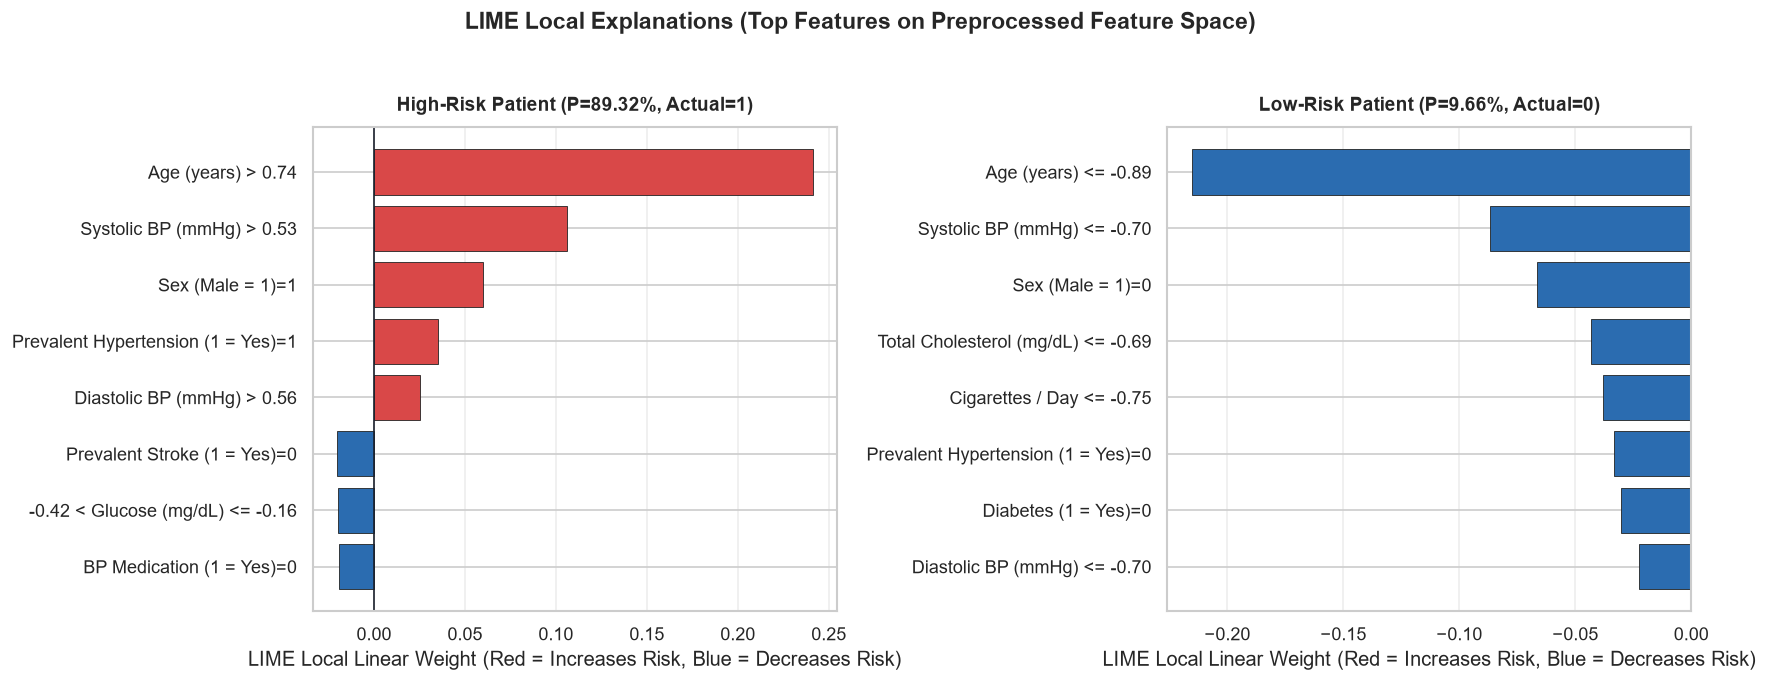

In [9]:
lime_explainer, _ = build_lime_explainer(pipeline, X_train)
classifier = pipeline.named_steps["classifier"]

lime_high = lime_explainer.explain_instance(
    X_test_proc.iloc[high_pos].values,
    classifier.predict_proba,
    num_features=8,
)
lime_low = lime_explainer.explain_instance(
    X_test_proc.iloc[low_pos].values,
    classifier.predict_proba,
    num_features=8,
)

fig_lime = plot_lime_comparison(
    lime_high,
    lime_low,
    high_title=f"High-Risk Patient (P={high_exp['predicted_probability']:.2%}, Actual=1)",
    low_title=f"Low-Risk Patient (P={low_exp['predicted_probability']:.2%}, Actual=0)",
    save_path=REPORTS_DIR / "lime_local_explanations.png",
)
plt.show()


### Interpretation — LIME Local Explanations

- **High-Risk Patient:** LIME identifies **`Age (years) > 0.74`** (`+0.24`), **`Systolic BP > 0.53`** (`+0.11`), **`Sex (Male) = 1`** (`+0.06`), **`Prevalent Hypertension = 1`** (`+0.04`), and **`Diastolic BP > 0.56`** (`+0.03`) as the top risk-increasing rules, while normal glucose, absence of prior stroke, and not being on BP medication slightly offset risk.
- **Low-Risk Patient:** Every top LIME rule points toward lower CHD risk — **`Age <= -0.89`** (`-0.21`), **`Systolic BP <= -0.70`** (`-0.09`), **`Female Sex`** (`-0.07`), **`Total Cholesterol <= -0.69`** (`-0.04`), and **`Cigarettes / Day <= -0.75`** (`-0.04`).


## 4. Reusable Inference & Explanation API: `explain_patient(patient_df)`

We verify `explain_patient(patient_df)` from `src/explain.py`, which takes a single-row DataFrame and returns a dictionary containing `predicted_probability`, `predicted_label`, `threshold`, and the top 5 contributing features with direction (`increases risk` / `decreases risk`).


In [10]:
# Demonstrate calling explain_patient(patient_df) directly with default loaded context
high_result = explain_patient(X_test.iloc[[high_pos]])
low_result = explain_patient(X_test.iloc[[low_pos]])

print("explain_patient(high_risk_patient):")
print(json.dumps(high_result, indent=2))

print("\nexplain_patient(low_risk_patient):")
print(json.dumps(low_result, indent=2))


explain_patient(high_risk_patient):
{
  "predicted_probability": 0.8932,
  "predicted_label": 1,
  "threshold": 0.41,
  "top_features": [
    {
      "feature": "Systolic BP (mmHg)",
      "raw_feature": "sysBP",
      "shap_value": 0.9105,
      "abs_shap_value": 0.9105,
      "direction": "increases risk",
      "value": 215.0
    },
    {
      "feature": "Age (years)",
      "raw_feature": "age",
      "shap_value": 0.7435,
      "abs_shap_value": 0.7435,
      "direction": "increases risk",
      "value": 61.0
    },
    {
      "feature": "Cigarettes / Day",
      "raw_feature": "cigsPerDay",
      "shap_value": 0.2533,
      "abs_shap_value": 0.2533,
      "direction": "increases risk",
      "value": 20.0
    },
    {
      "feature": "Diastolic BP (mmHg)",
      "raw_feature": "diaBP",
      "shap_value": 0.2434,
      "abs_shap_value": 0.2434,
      "direction": "increases risk",
      "value": 129.0
    },
    {
      "feature": "Sex (Male = 1)",
      "raw_feature": "male",

### Interpretation — `explain_patient(patient_df)` Output

- `explain_patient(patient_df)` accepts raw patient rows (handling missing values and scaling automatically through the saved pipeline) and returns a JSON-serializable dictionary with `predicted_probability`, `predicted_label` (evaluated against the tuned `0.41` threshold), and the top 5 SHAP-ranked drivers with clear `"increases risk"` / `"decreases risk"` labels — ready to power the CardioSense Streamlit interface (`app/`).


## 5. Comparison: SHAP vs. LIME

| Dimension | SHAP (`LinearExplainer`) | LIME (`LimeTabularExplainer`) |
| :--- | :--- | :--- |
| **Theoretical Guarantee** | Exact Shapley values grounded in cooperative game theory (local accuracy, consistency, missingness). | Approximate local linear surrogate fitted on randomly perturbed neighbors around the instance. |
| **Determinism & Stability** | **100% deterministic** for `LogisticRegression` given the training background. | **Stochastic** (depends on random perturbation sampling and kernel width). |
| **Handling of Extreme Continuous Values** | Uses exact standardized feature values, so `sysBP = 215 mmHg` (`z = 3.76`) receives a larger attribution (`+0.91`) than `age = 61` (`+0.74`). | Discretizes continuous features into **quartiles** (`sysBP > 0.53`), compressing extreme hypertension into the same top bin as moderate hypertension — causing `Age > 0.74` to rank ahead of `Systolic BP`. |
| **Global + Local Consistency** | Naturally aggregates exact local attributions into global summaries (beeswarm & mean `\|SHAP\|`). | Strictly local; does not directly sum to a consistent global model decomposition. |
| **Best Use in CardioSense** | Primary attribution engine (`explain_patient`) for reliable, exact, reproducible clinical risk breakdowns. | Complementary human-friendly rule check (`Age > ...`, `Systolic BP > ...`) for intuitive sanity checking. |

## 6. Final Explainability Summary

### Data Analysis Key Findings
- **Global risk hierarchy:** Across the `848`-patient test set, **`Age (years)`** (`0.48`), **`Cigarettes / Day`** (`0.23`), **`Systolic BP (mmHg)`** (`0.19`), **`Sex (Male = 1)`** (`0.13`), and **`Total Cholesterol (mg/dL)`** (`0.08`) dominate global SHAP importance.
- **Patient-level agreement:** Both SHAP and LIME agree on the primary clinical drivers for the high-risk (`P = 89.32%`) and low-risk (`P = 9.66%`) test patients, while SHAP accurately preserves the severity of extreme `Systolic BP` (`215 mmHg`).
- **Artifacts saved:** `src/explain.py`, `notebooks/03_explainability.ipynb`, and 5 plots in `reports/` (`shap_summary_beeswarm.png`, `shap_feature_importance_bar.png`, `shap_waterfall_high_risk.png`, `shap_waterfall_low_risk.png`, `lime_local_explanations.png`).

### Next Steps
- Integrate `explain_patient()` and `models/best_model.pkl` into an interactive Streamlit risk calculator and explanation dashboard inside `app/`.
